In [1]:
%matplotlib widget
import os, sys
ROOT_DIR = os.path.abspath('..') if os.path.basename(os.getcwd()) in ('visualization', 'notebooks', 'scripts') else os.path.abspath('.')
for _p in (ROOT_DIR, os.path.join(ROOT_DIR, 'src'), os.path.join(ROOT_DIR, 'visualization')):
    if _p not in sys.path:
        sys.path.insert(0, _p)
os.chdir(ROOT_DIR)
import numpy as np
import astropy.units as u
from astropy.coordinates import SkyCoord
from observables_matrix import *
from bound_labels import compute_bound_stars
from plot_swift_output import load_snapshot
import matplotlib.pyplot as plt

✅ Matplotlib LaTeX style initialisé (Police: helvet, Taille: 14)


Processing snapshot file: B_L_snapshot_0070.npy
IC_28  bound 6341  total 39758
IC_17  bound 0  total 31093
IC_9  bound 0  total 29747
IC_19  bound 0  total 24988
IC_26  bound 0  total 30189
IC_21  bound 0  total 42146
IC_81  bound 39825  total 42990
IC_75  bound 976  total 25651
IC_72  bound 0  total 30694
IC_86  bound 0  total 32192
IC_44  bound 0  total 44574
IC_43  bound 0  total 25820
IC_20  bound 0  total 27841
IC_6  bound 37248  total 45008
IC_18  bound 22642  total 26176
IC_1  bound 15716  total 29137
IC_8  bound 0  total 41317
IC_11  bound 27347  total 32701
IC_29  bound 0  total 27076
IC_16  bound 0  total 27551
IC_42  bound 11695  total 26837
IC_87  bound 0  total 48507
IC_73  bound 19182  total 30182
IC_74  bound 0  total 43610
IC_80  bound 0  total 33277
IC_69  bound 0  total 25626
IC_51  bound 3324  total 34780
IC_60  bound 0  total 47553
IC_34  bound 501  total 30801
IC_33  bound 20335  total 21306
IC_61  bound 0  total 40369
IC_59  bound 22407  total 26661
IC_66  bound 0

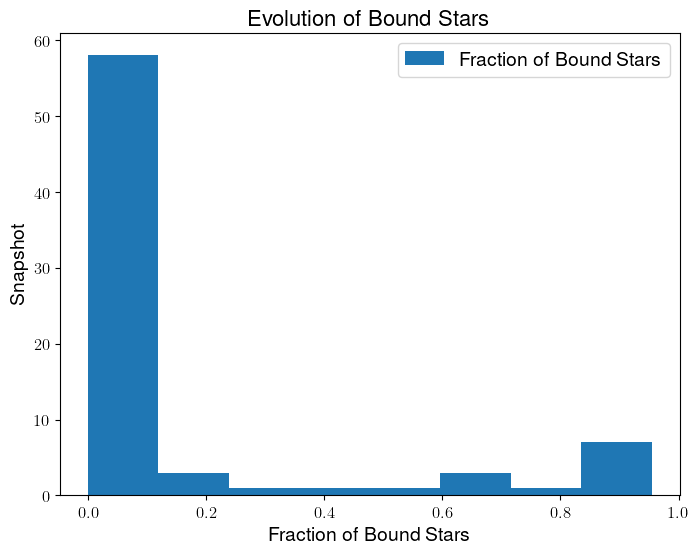

In [6]:
folder = "GNN-jed/labels_bound_stars/"
outputs_folders = [f for f in os.listdir(folder) if f.startswith("IC_")]
first_folder_path = folder + outputs_folders[0]
#snapshot_files = [f for f in os.listdir(first_folder_path) if f.startswith("B_L_")]

snapshot_files=["B_L_snapshot_0070.npy"]

for snapshot_file in snapshot_files:
    #plt.figure(figsize=(8, 6))
    print(f"Processing snapshot file: {snapshot_file}")
    i=0

    bound = []
    for output_folder in outputs_folders:
        
        full_path = os.path.join(folder, output_folder, snapshot_file)
        all = np.load(full_path)
        print(output_folder," bound", np.sum(all), " total", len(all))
        bound.append(np.sum(all)/len(all))
        i+=1

    plt.figure(figsize=(8, 6))
    plt.hist( bound, 8, label="Fraction of Bound Stars")
    plt.xlabel("Fraction of Bound Stars")
    plt.ylabel("Snapshot")
    plt.title("Evolution of Bound Stars")
    plt.legend()
    plt.show()
        

## We are going to compute the eccentricity for each orbit and plot it against the fraction of bound stars 


In [3]:

import os
import numpy as np
import pandas as pd

folder_bound = "GNN-jed/labels_bound_stars/"
outputs_folders = [f for f in os.listdir(folder_bound) if f.startswith("IC_")]
snapshot_files = ["B_L_snapshot_0020.npy"]

for snapshot_file in snapshot_files:
    print(f"Processing snapshot file: {snapshot_file}")
    
    data_list = []

    for output_folder in outputs_folders:
        full_path = os.path.join(folder_bound, output_folder, snapshot_file)
        
        if os.path.exists(full_path):
            all_stars = np.load(full_path)
            fraction = np.sum(all_stars) / len(all_stars)
            ic_number = int(output_folder.split('_')[1])
            
            data_list.append({"IC_Number": ic_number, "Bound_Fraction": fraction})

    df_bound = pd.DataFrame(data_list).sort_values(by="IC_Number").reset_index(drop=True)
    
    print("\n--- DataFrame ---")
    print(df_bound)

Processing snapshot file: B_L_snapshot_0020.npy

--- DataFrame ---
    IC_Number  Bound_Fraction
0           1        0.906682
1           3        0.835075
2           4        0.064201
3           5        0.000000
4           6        0.874489
..        ...             ...
70         81        0.958688
71         82        0.594665
72         83        0.467862
73         86        0.429486
74         87        0.618509

[75 rows x 2 columns]


In [4]:
# computing the eccentricity and adding it to the dataframe 
# first we load the orbit files and compute the eccentricity for each IC
folder_orbits = "make_ICs/orbits/"
orbit_files = [f for f in os.listdir(folder_orbits) if f.startswith("orbit_") and f.endswith(".txt")]

for orbit_file in orbit_files:
    full_path = os.path.join(folder_orbits, orbit_file)
    data = np.loadtxt(full_path, skiprows=1)
    
    x = data[:, 0]
    y = data[:, 1]
    z = data[:, 2]
    vx = data[:, 3]
    vy = data[:, 4]
    vz = data[:, 5]
    
    # computing r_p and r_a
    r = np.sqrt(x**2 + y**2 + z**2)
    r_p = np.min(r)
    r_a = np.max(r)
    e = (r_a - r_p) / (r_a + r_p)  # Eccentricity
    
    ic_number = int(orbit_file.split('_')[1].split('.')[0])
    
    df_bound.loc[df_bound["IC_Number"] == ic_number, "Eccentricity"] = e 
    
print("\n--- Updated DataFrame with Eccentricity ---")
print(df_bound)


--- Updated DataFrame with Eccentricity ---
    IC_Number  Bound_Fraction  Eccentricity
0           1        0.906682      0.601218
1           3        0.835075      0.504243
2           4        0.064201      0.494165
3           5        0.000000      0.237900
4           6        0.874489      0.384663
..        ...             ...           ...
70         81        0.958688      0.024295
71         82        0.594665      0.499949
72         83        0.467862      0.420612
73         86        0.429486      0.484690
74         87        0.618509      0.772331

[75 rows x 3 columns]


### Plotting fraction of bound stars against eccentricity

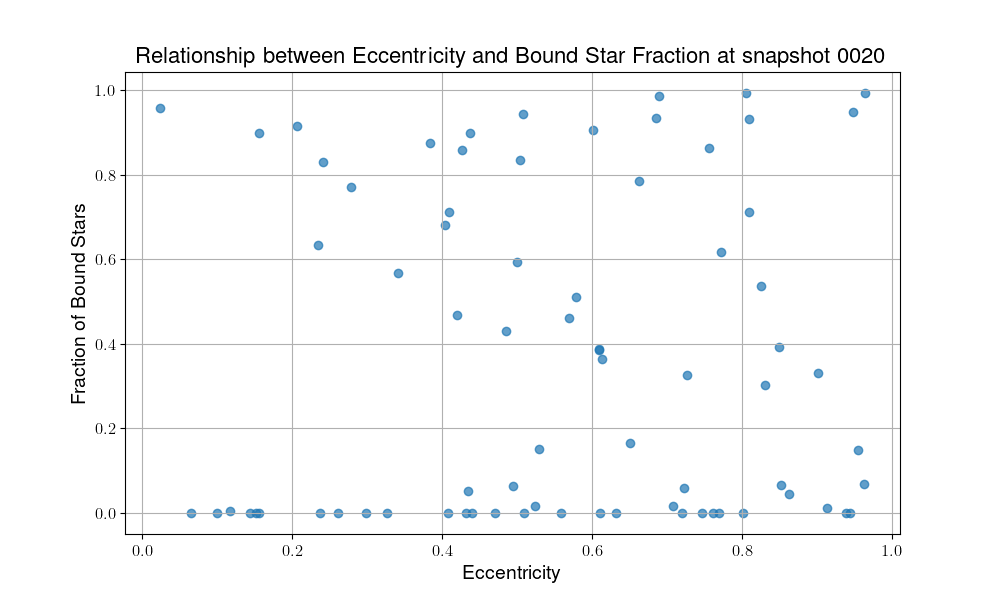

In [5]:
# Plotting the fraction of bound stars against eccentricity
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(df_bound["Eccentricity"], df_bound["Bound_Fraction"], alpha=0.7)
plt.xlabel("Eccentricity")
plt.ylabel("Fraction of Bound Stars")
plt.title("Relationship between Eccentricity and Bound Star Fraction at snapshot 0020")
plt.grid(True)
plt.show()

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from adri_plotstyle import init_plot_style
init_plot_style()

# plot folder 
plot_folder = "frac_plots_5/"
if not os.path.exists(plot_folder):
    os.makedirs(plot_folder)

# first we load the orbit files and compute the eccentricity for each IC
folder_orbits = "make_ICs/orbits/"
orbit_files = [f for f in os.listdir(folder_orbits) if f.startswith("orbit_") and f.endswith(".txt")]

folder_bound = "GNN-jed/labels_bound_stars/"
outputs_folders = [f for f in os.listdir(folder_bound) if f.startswith("IC_")]

first_folder_path = os.path.join(folder_bound, outputs_folders[0])
snapshot_files = [f for f in os.listdir(first_folder_path) if f.startswith("B_L_")]
#snapshot_files = ["B_L_snapshot_0060.npy"]

for snapshot_file in snapshot_files:
    print(f"Processing snapshot file: {snapshot_file}")
    
    data_list = []

    for output_folder in outputs_folders:
        full_path = os.path.join(folder_bound, output_folder, snapshot_file)
        
        if os.path.exists(full_path):
            all_stars = np.load(full_path)
            fraction = np.sum(all_stars) / len(all_stars)
            ic_number = int(output_folder.split('_')[1])
            
            data_list.append({"IC_Number": ic_number, "Bound_Fraction": fraction})

    df_bound = pd.DataFrame(data_list).sort_values(by="IC_Number").reset_index(drop=True)
    
    for orbit_file in orbit_files:
        full_path = os.path.join(folder_orbits, orbit_file)
        data = np.loadtxt(full_path, skiprows=1)
        
        x = data[:, 0]
        y = data[:, 1]
        z = data[:, 2]
        vx = data[:, 3]
        vy = data[:, 4]
        vz = data[:, 5]
        
        # computing r_p and r_a
        r = np.sqrt(x**2 + y**2 + z**2)
        r_p = np.min(r)
        r_a = np.max(r)
        e = (r_a - r_p) / (r_a + r_p)  # Eccentricity
        
        ic_number = int(orbit_file.split('_')[1].split('.')[0])
        df_bound.loc[df_bound["IC_Number"] == ic_number, "Eccentricity"] = e 

    snap_num = snapshot_file.split('_')[-1].replace('.npy', '')

    plt.figure(figsize=(10, 6))

    df_indx = df_bound["Bound_Fraction"] > 0.05
    plt.scatter(df_bound["Eccentricity"].loc[df_indx], df_bound["Bound_Fraction"].loc[df_indx], alpha=0.7)

    df_sorted = df_bound.loc[df_indx].sort_values(by="Eccentricity")
    
    # 2. Maintenant que tout est dans l'ordre, on extrait x et y en toute sécurité
    x = df_sorted["Eccentricity"].values
    y = df_sorted["Bound_Fraction"].values

    coefs = np.polyfit(x, y, 2)
    poly = np.poly1d(coefs)
    y_fit = poly(x)
    
    plt.plot(x, y_fit, color='red', linewidth=3, label="$/mathrm{Tendance\ (Fit)}$")
    plt.xlabel("$\\mathrm{Eccentricity}$")
    plt.ylabel("$\\mathrm{Fraction\ of\ Bound\ Stars}$")
    plt.title(f"$\\mathrm{{Snapshot\\ {snap_num}}}$")
    plt.grid(True)
    plt.xlim(0, 1)
    plt.ylim(0, 1)

    #save fig 
    plt.savefig(f"{plot_folder}fraction_bound_stars_snapshot_{snap_num}.png", dpi=300)
    plt.close()

✅ Matplotlib LaTeX style initialisé (Police: helvet, Taille: 12)
Processing snapshot file: B_L_snapshot_0024.npy
Processing snapshot file: B_L_snapshot_0030.npy
Processing snapshot file: B_L_snapshot_0018.npy
Processing snapshot file: B_L_snapshot_0019.npy
Processing snapshot file: B_L_snapshot_0031.npy
Processing snapshot file: B_L_snapshot_0025.npy
Processing snapshot file: B_L_snapshot_0033.npy
Processing snapshot file: B_L_snapshot_0027.npy
Processing snapshot file: B_L_snapshot_0026.npy
Processing snapshot file: B_L_snapshot_0032.npy
Processing snapshot file: B_L_snapshot_0036.npy
Processing snapshot file: B_L_snapshot_0022.npy
Processing snapshot file: B_L_snapshot_0023.npy
Processing snapshot file: B_L_snapshot_0037.npy
Processing snapshot file: B_L_snapshot_0009.npy
Processing snapshot file: B_L_snapshot_0021.npy
Processing snapshot file: B_L_snapshot_0035.npy
Processing snapshot file: B_L_snapshot_0034.npy
Processing snapshot file: B_L_snapshot_0020.npy
Processing snapshot fil

✅ Matplotlib LaTeX style initialisé (Police: helvet, Taille: 12)


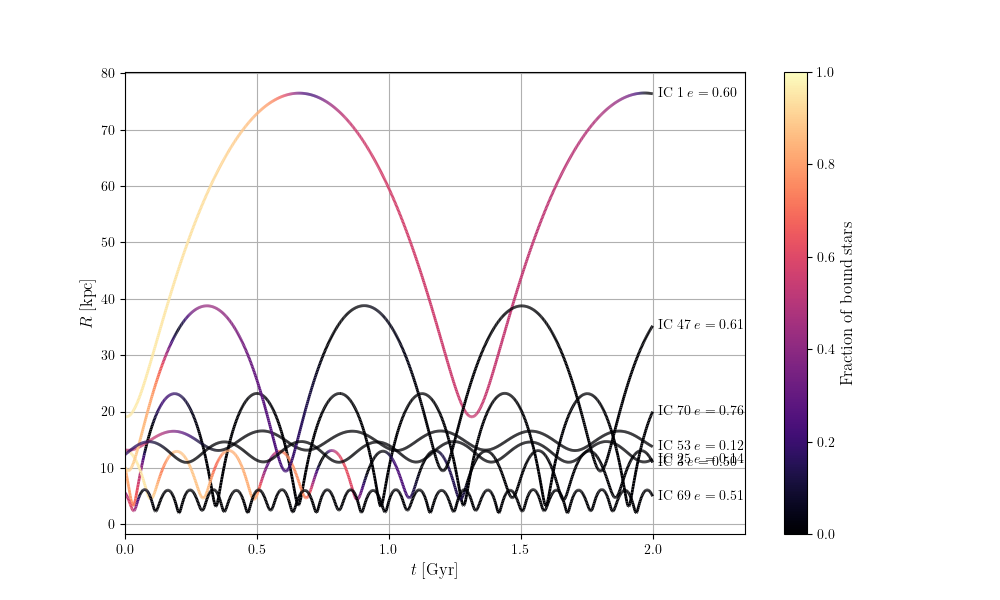

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from adri_plotstyle import init_plot_style

init_plot_style(14)

# first we load the orbit files
folder_orbits = "make_ICs/orbits/"
orbit_files = [f for f in os.listdir(folder_orbits) if f.startswith("orbit_") and f.endswith(".txt")]

folder_bound = "GNN-jed/labels_bound_stars/"
ic_list = [1,3,25,47, 53, 69, 70]
ic_all = "al"

# Setup figure
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True)
ax.set_xlabel(r'$t\ \mathrm{[Gyr]}$')
ax.set_ylabel(r'$R\ \mathrm{[kpc]}$')

# Variables pour stocker les collections et définir une échelle de couleur globale
line_collections = []
global_min_bound = float(0)
global_max_bound = float(1)

for orbits_file in orbit_files:
    ic_number = int(orbits_file.split('_')[1].split('.')[0])

    if ic_number in ic_list or ic_all == "all":
        # --- 1. Charger les orbites ---
        full_path = os.path.join(folder_orbits, orbits_file)
        data = np.loadtxt(full_path, skiprows=1)
        
        x = data[:, 0]
        y = data[:, 1]
        z = data[:, 2]

        r = np.sqrt(x**2 + y**2 + z**2)
        t = np.linspace(0, 2, len(r))
        
        # --- 2. Charger les bound stars (101 snapshots de 0 à 2 Gyr) ---
        bound_frac = []
        t_snapshots = np.linspace(0, 2, 101)
        
        for snap_idx in range(101):
            # Formatage du nom avec 4 zéros (ex: 0000, 0001, ..., 0100)
            label_file = os.path.join(folder_bound, f"IC_{ic_number}", f"B_L_snapshot_{snap_idx:04d}.npy")
            
            if os.path.exists(label_file):
                labels = np.load(label_file)
                num_bound = np.sum(labels) 
                bound_frac.append(num_bound/len(labels)) # Convertir en fraction de bound stars
            else:
                bound_frac.append(np.nan) # imagine missing a file

        bound_frac = np.array(bound_frac) # Convertir en fraction de bound stars
        
        # --- 3. Interpolate quantities on the grid
        bound_interp = np.interp(t, t_snapshots, bound_frac)
        
        
        # --- 4. Créer les segments continus pour LineCollection ---
        points = np.array([t, r]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        
        # La couleur du segment est la moyenne des quantités aux deux extrémités
        colors_for_segments = 0.5 * (bound_interp[:-1] + bound_interp[1:])
        
        # Création de la ligne multi-couleurs
        lc = LineCollection(segments, cmap='magma') # Tu peux changer 'viridis' par 'plasma', 'magma', etc.
        lc.set_array(colors_for_segments)
        lc.set_linewidth(2)
        
        ax.add_collection(lc)
        line_collections.append(lc)

        # getting the mins and the max to compute the exxenctricity
        r_a = np.max(r)
        r_p = np.min(r)
        e = (r_a - r_p) / (r_a + r_p)  # Eccentricity

        ax.text(t[-1] + 0.02, r[-1], f'$\mathrm{{IC\ {ic_number}}}\ e={e:.2f}$', 
                fontsize=10, 
                verticalalignment='center', 
                fontweight='bold',
                color='black')
ax.autoscale()

if line_collections:
    # making sure it has the right scale
    for lc in line_collections:
        lc.set_clim(global_min_bound, global_max_bound)
        
    # colorbar on the side
    cbar = fig.colorbar(line_collections[0], ax=ax)
    cbar.set_label('$\mathrm{Fraction\ of\ bound\ stars}$')

plt.xlim(0, 2.35)
plt.savefig("plots/R_vs_t_all.png", dpi=600, bbox_inches='tight')
plt.show()


## Binning the results based on the first pericenter of the orbit and making a 6 pannel plot

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from adri_plotstyle import init_plot_style

init_plot_style(14)

# first we load the orbit files
folder_orbits = "make_ICs/orbits/"
orbit_files = [f for f in os.listdir(folder_orbits) if f.startswith("orbit_") and f.endswith(".txt")]

folder_bound = "GNN-jed/labels_bound_stars/"
ic_list = [1,3,25,47, 53, 69, 70]
ic_all = "al"

# Setup figure
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True)
ax.set_xlabel(r'$t\ \mathrm{[Gyr]}$')
ax.set_ylabel(r'$R\ \mathrm{[kpc]}$')

# Variables pour stocker les collections et définir une échelle de couleur globale
line_collections = []
global_min_bound = float(0)
global_max_bound = float(1)

for orbits_file in orbit_files:
    ic_number = int(orbits_file.split('_')[1].split('.')[0])

    if ic_number in ic_list or ic_all == "all":
        # --- 1. Charger les orbites ---
        full_path = os.path.join(folder_orbits, orbits_file)
        data = np.loadtxt(full_path, skiprows=1)
        
        x = data[:, 0]
        y = data[:, 1]
        z = data[:, 2]

        r = np.sqrt(x**2 + y**2 + z**2)
        t = np.linspace(0, 2, len(r))
        
        # --- 2. Charger les bound stars (101 snapshots de 0 à 2 Gyr) ---
        bound_frac = []
        t_snapshots = np.linspace(0, 2, 101)
        
        for snap_idx in range(101):
            # Formatage du nom avec 4 zéros (ex: 0000, 0001, ..., 0100)
            label_file = os.path.join(folder_bound, f"IC_{ic_number}", f"B_L_snapshot_{snap_idx:04d}.npy")
            
            if os.path.exists(label_file):
                labels = np.load(label_file)
                num_bound = np.sum(labels) 
                bound_frac.append(num_bound/len(labels)) # Convertir en fraction de bound stars
            else:
                bound_frac.append(np.nan) # imagine missing a file

        bound_frac = np.array(bound_frac) # Convertir en fraction de bound stars
        
        # --- 3. Interpolate quantities on the grid
        bound_interp = np.interp(t, t_snapshots, bound_frac)
        
        
        # --- 4. Créer les segments continus pour LineCollection ---
        points = np.array([t, r]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        
        # La couleur du segment est la moyenne des quantités aux deux extrémités
        colors_for_segments = 0.5 * (bound_interp[:-1] + bound_interp[1:])
        
        # Création de la ligne multi-couleurs
        lc = LineCollection(segments, cmap='magma') # Tu peux changer 'viridis' par 'plasma', 'magma', etc.
        lc.set_array(colors_for_segments)
        lc.set_linewidth(2)
        
        ax.add_collection(lc)
        line_collections.append(lc)

        # getting the mins and the max to compute the exxenctricity
        r_a = np.max(r)
        r_p = np.min(r)
        e = (r_a - r_p) / (r_a + r_p)  # Eccentricity

        ax.text(t[-1] + 0.02, r[-1], f'$\mathrm{{IC\ {ic_number}}}\ e={e:.2f}$', 
                fontsize=10, 
                verticalalignment='center', 
                fontweight='bold',
                color='black')
ax.autoscale()

if line_collections:
    # making sure it has the right scale
    for lc in line_collections:
        lc.set_clim(global_min_bound, global_max_bound)
        
    # colorbar on the side
    cbar = fig.colorbar(line_collections[0], ax=ax)
    cbar.set_label('$\mathrm{Fraction\ of\ bound\ stars}$')

plt.xlim(0, 2.35)
plt.savefig("plots/R_vs_t_all.png", dpi=600, bbox_inches='tight')
plt.show()

✅ Matplotlib LaTeX style initialisé (Police: helvet, Taille: 12)


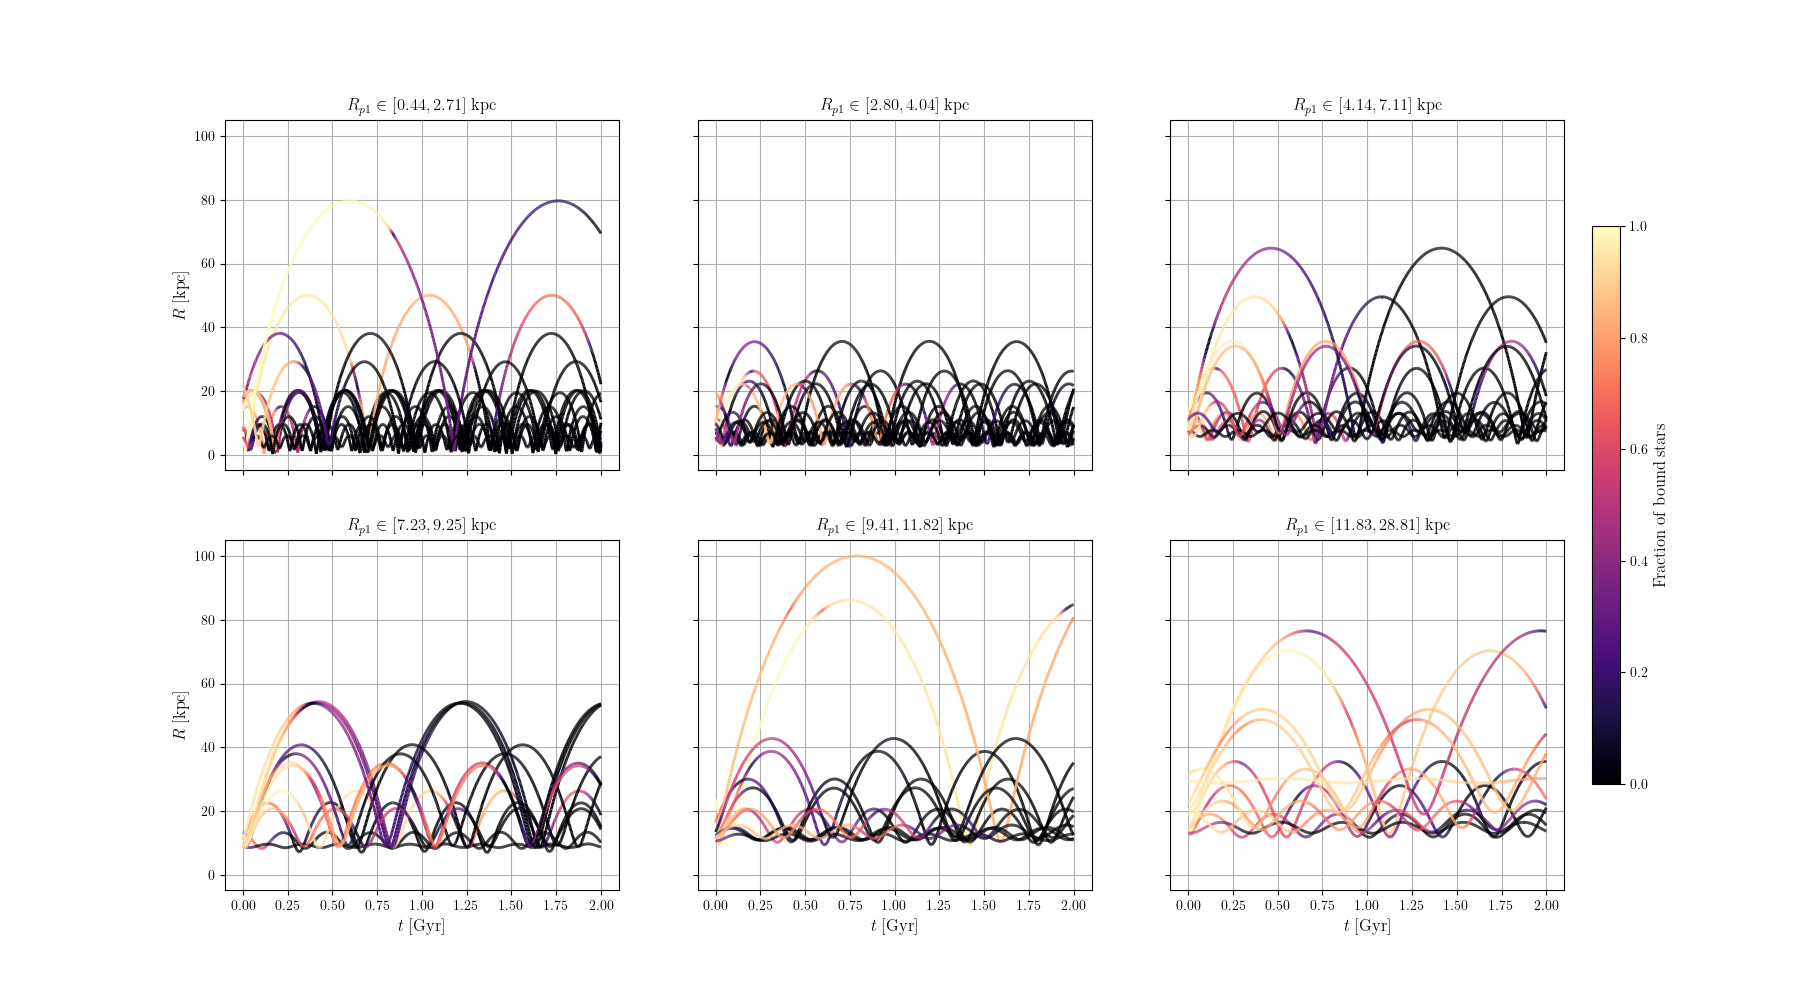

In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from adri_plotstyle import init_plot_style

init_plot_style(14)

folder_orbits = "make_ICs/orbits/"
orbit_files = [f for f in os.listdir(folder_orbits) if f.startswith("orbit_") and f.endswith(".txt")]
folder_bound = "GNN-jed/labels_bound_stars/"
ic_list = [1, 3, 25, 47, 53, 69, 70]
ic_all = "all"

orbit_data = []

for orbits_file in orbit_files:
    ic_number = int(orbits_file.split('_')[1].split('.')[0])
    
    if ic_number in ic_list or ic_all == "all":
        full_path = os.path.join(folder_orbits, orbits_file)
        data = np.loadtxt(full_path, skiprows=1)
        
        r = np.sqrt(data[:, 0]**2 + data[:, 1]**2 + data[:, 2]**2)
        t = np.linspace(0, 2, len(r))
        
        dr = np.diff(r)
        pericenters = np.where((dr[:-1] < 0) & (dr[1:] > 0))[0] + 1
        rp1 = r[pericenters[0]] if len(pericenters) > 0 else np.min(r)
        
        r_a, r_p = np.max(r), np.min(r)
        e = (r_a - r_p) / (r_a + r_p)
        
        bound_frac = []
        t_snapshots = np.linspace(0, 2, 101)
        
        for snap_idx in range(101):
            label_file = os.path.join(folder_bound, f"IC_{ic_number}", f"B_L_snapshot_{snap_idx:04d}.npy")
            if os.path.exists(label_file):
                labels = np.load(label_file)
                bound_frac.append(np.sum(labels) / len(labels))
            else:
                bound_frac.append(np.nan)
                
        bound_interp = np.interp(t, t_snapshots, np.array(bound_frac))
        orbit_data.append((rp1, ic_number, t, r, bound_interp, e))

orbit_data.sort(key=lambda x: x[0])
split_indices = np.array_split(range(len(orbit_data)), 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)
axes = axes.flatten()

lc = None 

for i, indices in enumerate(split_indices):
    ax = axes[i]
    ax.grid(True)
    if len(indices) == 0:
        continue
        
    rp1_min = orbit_data[indices[0]][0]
    rp1_max = orbit_data[indices[-1]][0]
    ax.set_title(rf'$R_{{p1}} \in [{rp1_min:.2f}, {rp1_max:.2f}]\ \mathrm{{kpc}}$', fontsize=12)
    
    for idx in indices:
        rp1, ic_number, t, r, bound_interp, e = orbit_data[idx]
        
        points = np.array([t, r]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        colors = 0.5 * (bound_interp[:-1] + bound_interp[1:])
        
        lc = LineCollection(segments, cmap='magma')
        lc.set_array(colors)
        lc.set_linewidth(2)
        lc.set_clim(0.0, 1.0)
        
        ax.add_collection(lc)
        # ax.text(t[-1] + 0.02, r[-1], f'$\mathrm{{IC\ {ic_number}}}\ e={e:.2f}$', 
        #         fontsize=8, va='center', fontweight='bold', color='black')
    
    ax.autoscale()
    # ax.set_xlim(0, 2.35)
    
    if i >= 3:
        ax.set_xlabel(r'$t\ \mathrm{[Gyr]}$')
    if i % 3 == 0:
        ax.set_ylabel(r'$R\ \mathrm{[kpc]}$')

if lc is not None:
    cbar = fig.colorbar(lc, ax=axes.tolist(), fraction=0.02, pad=0.02)
    cbar.set_label('$\mathrm{Fraction\ of\ bound\ stars}$')

plt.savefig("plots/R_vs_t_6panels_rp1.png", dpi=600, bbox_inches='tight')
plt.show()

✅ Matplotlib LaTeX style initialisé (Police: helvet, Taille: 12)


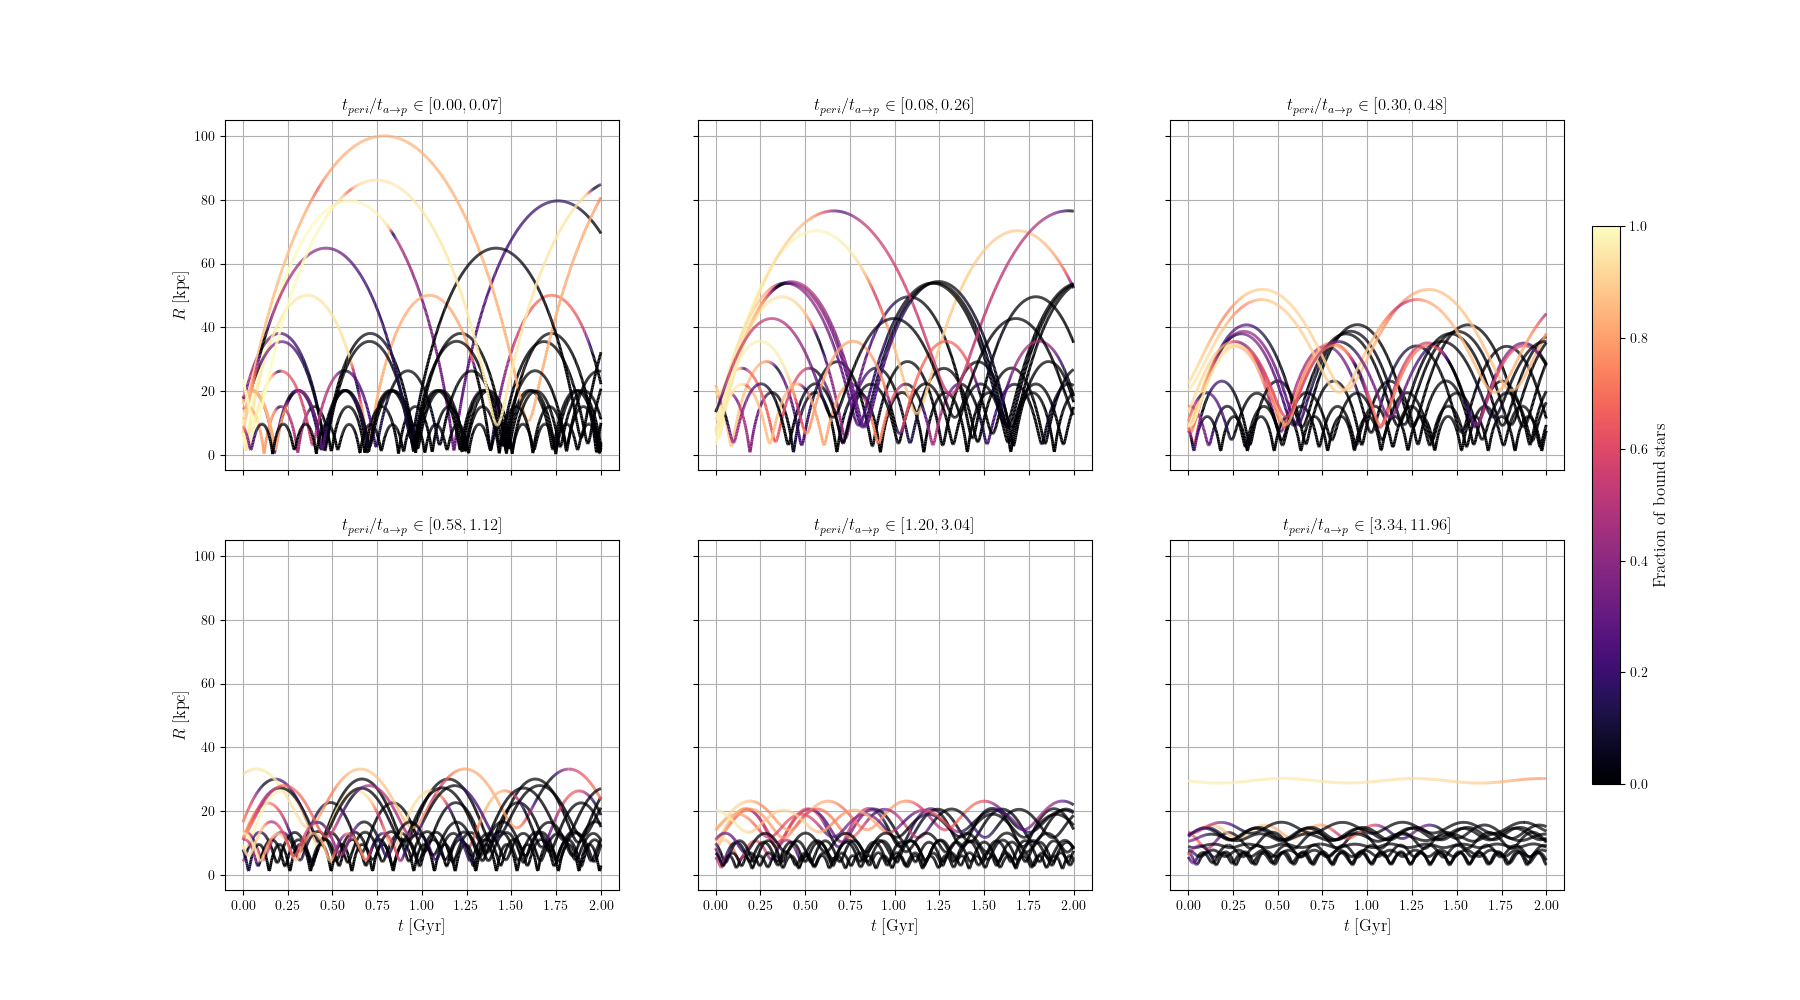

In [14]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from adri_plotstyle import init_plot_style

init_plot_style(14)

folder_orbits = "make_ICs/orbits/"
orbit_files = [f for f in os.listdir(folder_orbits) if f.startswith("orbit_") and f.endswith(".txt")]
folder_bound = "GNN-jed/labels_bound_stars/"
ic_list = [1, 3, 25, 47, 53, 69, 70]
ic_all = "all"

orbit_data = []

for orbits_file in orbit_files:
    ic_number = int(orbits_file.split('_')[1].split('.')[0])
    
    if ic_number in ic_list or ic_all == "all":
        full_path = os.path.join(folder_orbits, orbits_file)
        data = np.loadtxt(full_path, skiprows=1)
        
        r = np.sqrt(data[:, 0]**2 + data[:, 1]**2 + data[:, 2]**2)
        t = np.linspace(0, 2, len(r))
        dt = t[1] - t[0]
        
        r_a, r_p = np.max(r), np.min(r)
        e = (r_a - r_p) / (r_a + r_p)
        
        t_peri = np.sum(r <= 1.1 * r_p) * dt
        
        dr = np.diff(r)
        pericenters = np.where((dr[:-1] < 0) & (dr[1:] > 0))[0] + 1
        apocenters = np.where((dr[:-1] > 0) & (dr[1:] < 0))[0] + 1
        
        if len(pericenters) > 0 and len(apocenters) > 0:
            t_apo_to_peri = np.abs(t[pericenters[0]] - t[apocenters[0]])
        else:
            t_apo_to_peri = np.abs(t[np.argmin(r)] - t[np.argmax(r)])
            
        t_apo_to_peri = max(t_apo_to_peri, 1e-5)
        t_ratio = t_peri / t_apo_to_peri
        
        bound_frac = []
        t_snapshots = np.linspace(0, 2, 101)
        
        for snap_idx in range(101):
            label_file = os.path.join(folder_bound, f"IC_{ic_number}", f"B_L_snapshot_{snap_idx:04d}.npy")
            if os.path.exists(label_file):
                labels = np.load(label_file)
                bound_frac.append(np.sum(labels) / len(labels))
            else:
                bound_frac.append(np.nan)
                
        bound_interp = np.interp(t, t_snapshots, np.array(bound_frac))
        orbit_data.append((t_ratio, ic_number, t, r, bound_interp, e))

orbit_data.sort(key=lambda x: x[0])
split_indices = np.array_split(range(len(orbit_data)), 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)
axes = axes.flatten()

lc = None 

for i, indices in enumerate(split_indices):
    ax = axes[i]
    ax.grid(True)
    if len(indices) == 0:
        continue
        
    ratio_min = orbit_data[indices[0]][0]
    ratio_max = orbit_data[indices[-1]][0]
    ax.set_title(rf'$t_{{peri}}/t_{{a \to p}} \in [{ratio_min:.2f}, {ratio_max:.2f}]$', fontsize=12)
    
    for idx in indices:
        t_ratio, ic_number, t, r, bound_interp, e = orbit_data[idx]
        
        points = np.array([t, r]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        colors = 0.5 * (bound_interp[:-1] + bound_interp[1:])
        
        lc = LineCollection(segments, cmap='magma')
        lc.set_array(colors)
        lc.set_linewidth(2)
        lc.set_clim(0.0, 1.0)
        ax.add_collection(lc)
    
    ax.autoscale()
    
    if i >= 3:
        ax.set_xlabel(r'$t\ \mathrm{[Gyr]}$')
    if i % 3 == 0:
        ax.set_ylabel(r'$R\ \mathrm{[kpc]}$')

if lc is not None:
    cbar = fig.colorbar(lc, ax=axes.tolist(), fraction=0.02, pad=0.02)
    cbar.set_label('$\mathrm{Fraction\ of\ bound\ stars}$')

plt.savefig("plots/R_vs_t_6panels_tratio.png", dpi=600, bbox_inches='tight')
plt.show()

✅ Matplotlib LaTeX style initialisé (Police: helvet, Taille: 12)


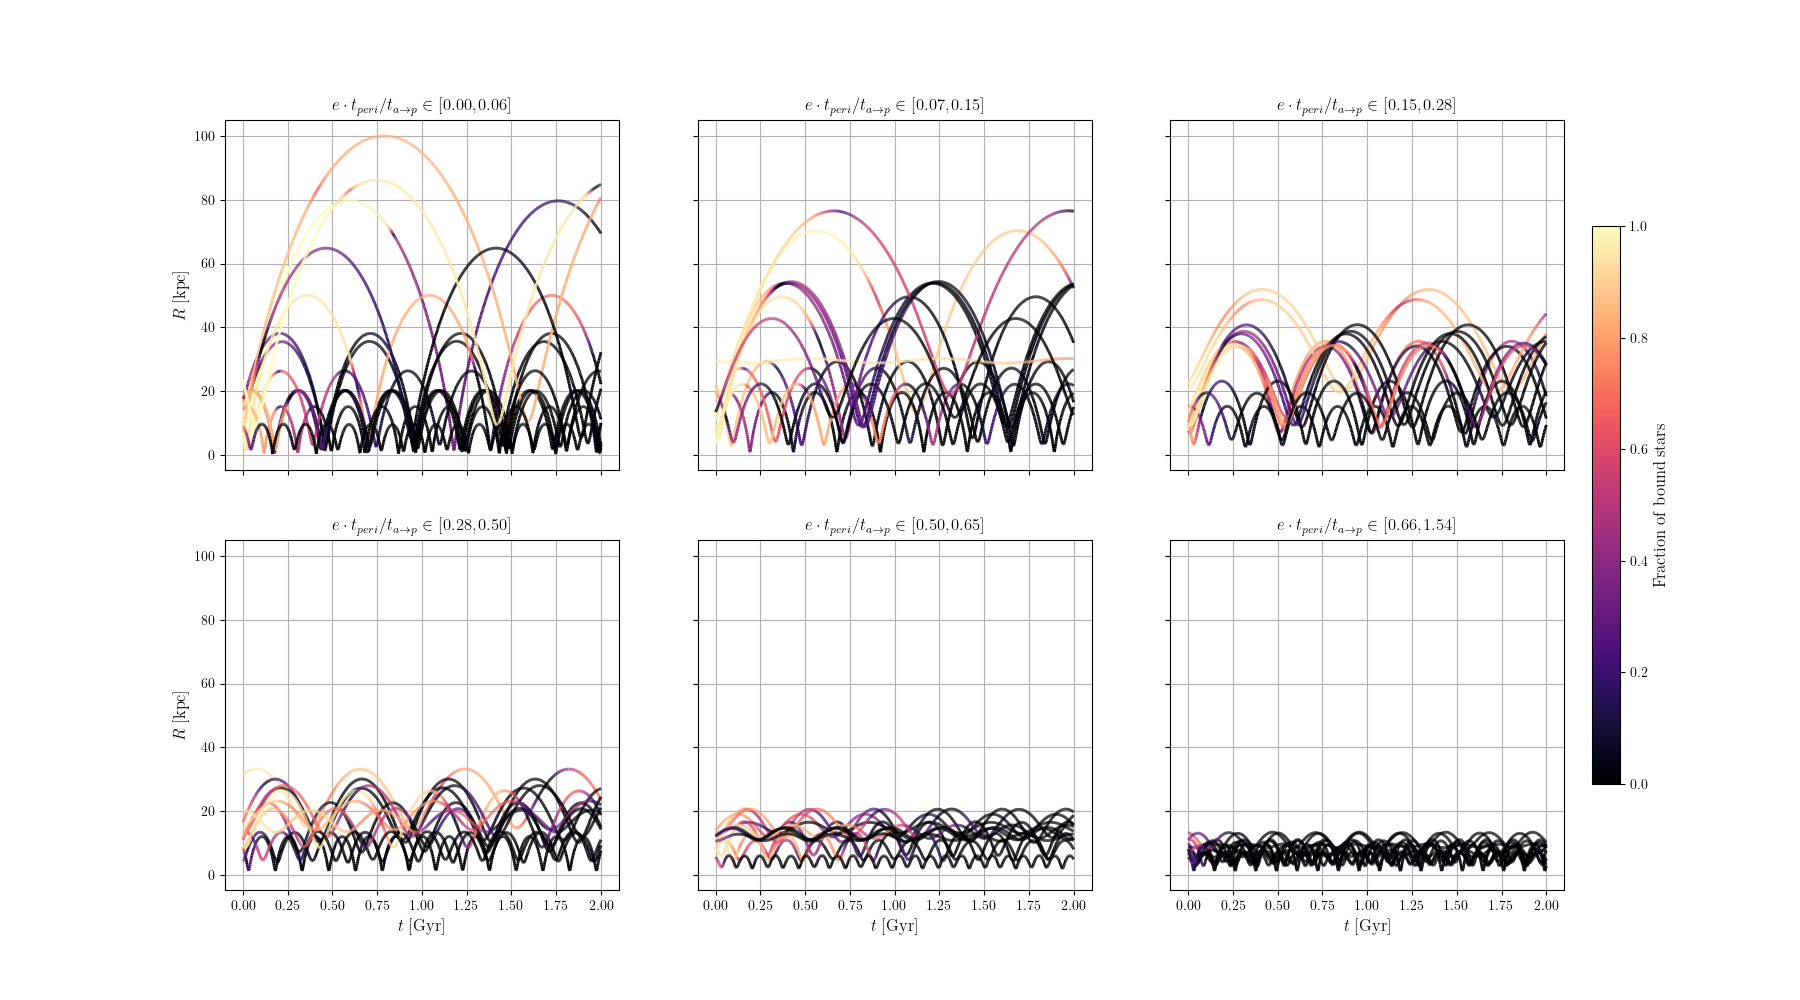

In [16]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from adri_plotstyle import init_plot_style

init_plot_style(14)

folder_orbits = "make_ICs/orbits/"
orbit_files = [f for f in os.listdir(folder_orbits) if f.startswith("orbit_") and f.endswith(".txt")]
folder_bound = "GNN-jed/labels_bound_stars/"
ic_list = [1, 3, 25, 47, 53, 69, 70]
ic_all = "all"

orbit_data = []

for orbits_file in orbit_files:
    ic_number = int(orbits_file.split('_')[1].split('.')[0])
    
    if ic_number in ic_list or ic_all == "all":
        full_path = os.path.join(folder_orbits, orbits_file)
        data = np.loadtxt(full_path, skiprows=1)
        
        r = np.sqrt(data[:, 0]**2 + data[:, 1]**2 + data[:, 2]**2)
        t = np.linspace(0, 2, len(r))
        dt = t[1] - t[0]
        
        r_a, r_p = np.max(r), np.min(r)
        e = (r_a - r_p) / (r_a + r_p)
        
        t_peri = np.sum(r <= 1.1 * r_p) * dt
        
        dr = np.diff(r)
        pericenters = np.where((dr[:-1] < 0) & (dr[1:] > 0))[0] + 1
        apocenters = np.where((dr[:-1] > 0) & (dr[1:] < 0))[0] + 1
        
        if len(pericenters) > 0 and len(apocenters) > 0:
            t_apo_to_peri = np.abs(t[pericenters[0]] - t[apocenters[0]])
        else:
            t_apo_to_peri = np.abs(t[np.argmin(r)] - t[np.argmax(r)])
            
        t_apo_to_peri = max(t_apo_to_peri, 1e-5)
        metric = (t_peri / t_apo_to_peri) * e
        
        bound_frac = []
        t_snapshots = np.linspace(0, 2, 101)
        
        for snap_idx in range(101):
            label_file = os.path.join(folder_bound, f"IC_{ic_number}", f"B_L_snapshot_{snap_idx:04d}.npy")
            if os.path.exists(label_file):
                labels = np.load(label_file)
                bound_frac.append(np.sum(labels) / len(labels))
            else:
                bound_frac.append(np.nan)
                
        bound_interp = np.interp(t, t_snapshots, np.array(bound_frac))
        orbit_data.append((metric, ic_number, t, r, bound_interp, e))

orbit_data.sort(key=lambda x: x[0])
split_indices = np.array_split(range(len(orbit_data)), 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)
axes = axes.flatten()

lc = None 

for i, indices in enumerate(split_indices):
    ax = axes[i]
    ax.grid(True)
    if len(indices) == 0:
        continue
        
    metric_min = orbit_data[indices[0]][0]
    metric_max = orbit_data[indices[-1]][0]
    ax.set_title(rf'$e \cdot t_{{peri}}/t_{{a \to p}} \in [{metric_min:.2f}, {metric_max:.2f}]$', fontsize=12)
    
    for idx in indices:
        metric, ic_number, t, r, bound_interp, e = orbit_data[idx]
        
        points = np.array([t, r]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        colors = 0.5 * (bound_interp[:-1] + bound_interp[1:])
        
        lc = LineCollection(segments, cmap='magma')
        lc.set_array(colors)
        lc.set_linewidth(2)
        lc.set_clim(0.0, 1.0)
        
        ax.add_collection(lc)
    
    ax.autoscale()
    
    if i >= 3:
        ax.set_xlabel(r'$t\ \mathrm{[Gyr]}$')
    if i % 3 == 0:
        ax.set_ylabel(r'$R\ \mathrm{[kpc]}$')

if lc is not None:
    cbar = fig.colorbar(lc, ax=axes.tolist(), fraction=0.02, pad=0.02)
    cbar.set_label('$\mathrm{Fraction\ of\ bound\ stars}$')

plt.savefig("plots/R_vs_t_6panels_emetric.png", dpi=600, bbox_inches='tight')
plt.show()

✅ Matplotlib LaTeX style initialisé (Police: helvet, Taille: 12)


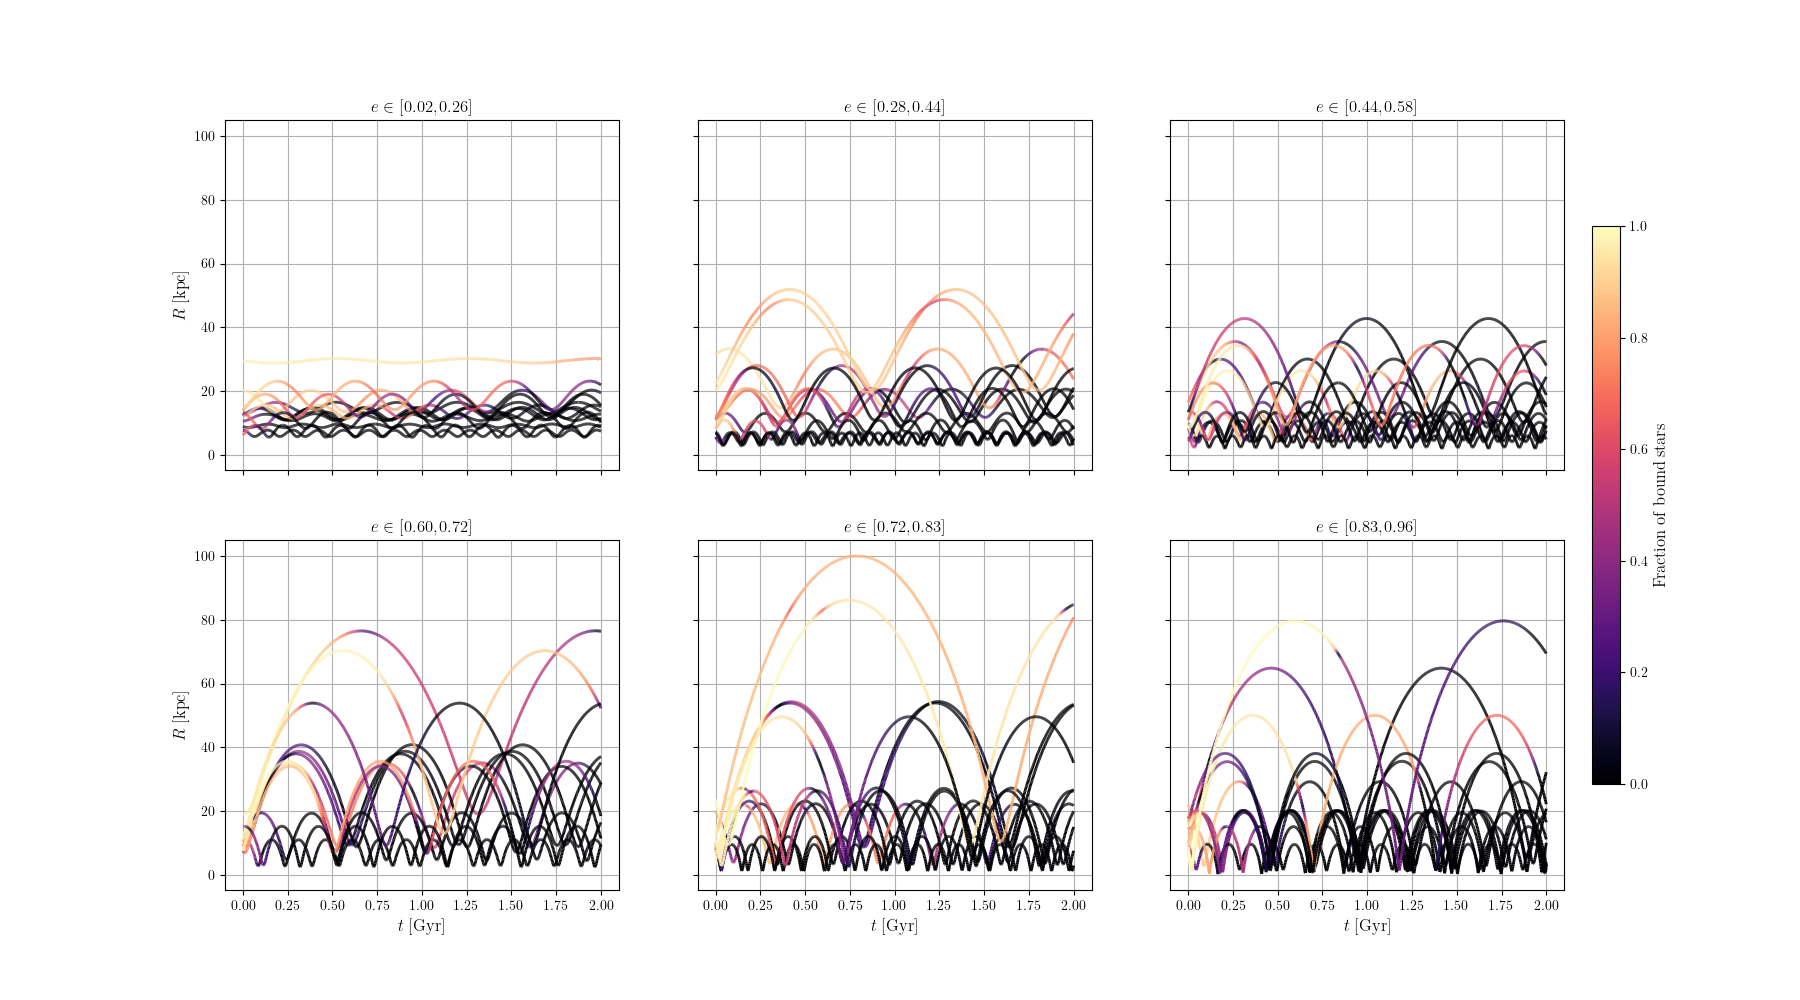

In [21]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from adri_plotstyle import init_plot_style

init_plot_style(14)

folder_orbits = "make_ICs/orbits/"
orbit_files = [f for f in os.listdir(folder_orbits) if f.startswith("orbit_") and f.endswith(".txt")]
folder_bound = "GNN-jed/labels_bound_stars/"
ic_list = [1, 3, 25, 47, 53, 69, 70]
ic_all = "all"

orbit_data = []

for orbits_file in orbit_files:
    ic_number = int(orbits_file.split('_')[1].split('.')[0])
    
    if ic_number in ic_list or ic_all == "all":
        full_path = os.path.join(folder_orbits, orbits_file)
        data = np.loadtxt(full_path, skiprows=1)
        
        r = np.sqrt(data[:, 0]**2 + data[:, 1]**2 + data[:, 2]**2)
        t = np.linspace(0, 2, len(r))
        dt = t[1] - t[0]
        
        r_a, r_p = np.max(r), np.min(r)
        e = (r_a - r_p) / (r_a + r_p)
        
        t_peri = np.sum(r <= 1.1 * r_p) * dt
        
        dr = np.diff(r)
        pericenters = np.where((dr[:-1] < 0) & (dr[1:] > 0))[0] + 1
        apocenters = np.where((dr[:-1] > 0) & (dr[1:] < 0))[0] + 1
        
        if len(pericenters) > 0 and len(apocenters) > 0:
            t_apo_to_peri = np.abs(t[pericenters[0]] - t[apocenters[0]])
        else:
            t_apo_to_peri = np.abs(t[np.argmin(r)] - t[np.argmax(r)])
            
        t_apo_to_peri = max(t_apo_to_peri, 1e-5)
        metric = (t_peri / t_apo_to_peri) * r_a/e
        metric = e
        
        bound_frac = []
        t_snapshots = np.linspace(0, 2, 101)
        
        for snap_idx in range(101):
            label_file = os.path.join(folder_bound, f"IC_{ic_number}", f"B_L_snapshot_{snap_idx:04d}.npy")
            if os.path.exists(label_file):
                labels = np.load(label_file)
                bound_frac.append(np.sum(labels) / len(labels))
            else:
                bound_frac.append(np.nan)
                
        bound_interp = np.interp(t, t_snapshots, np.array(bound_frac))
        orbit_data.append((metric, ic_number, t, r, bound_interp, e))

orbit_data.sort(key=lambda x: x[0])
split_indices = np.array_split(range(len(orbit_data)), 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)
axes = axes.flatten()

lc = None 

for i, indices in enumerate(split_indices):
    ax = axes[i]
    ax.grid(True)
    if len(indices) == 0:
        continue
        
    metric_min = orbit_data[indices[0]][0]
    metric_max = orbit_data[indices[-1]][0]
    ax.set_title(rf'$e \in [{metric_min:.2f}, {metric_max:.2f}]$', fontsize=12)
    
    for idx in indices:
        metric, ic_number, t, r, bound_interp, e = orbit_data[idx]
        
        points = np.array([t, r]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        colors = 0.5 * (bound_interp[:-1] + bound_interp[1:])
        
        lc = LineCollection(segments, cmap='magma')
        lc.set_array(colors)
        lc.set_linewidth(2)
        lc.set_clim(0.0, 1.0)
        ax.add_collection(lc)
    
    ax.autoscale()
    
    if i >= 3:
        ax.set_xlabel(r'$t\ \mathrm{[Gyr]}$')
    if i % 3 == 0:
        ax.set_ylabel(r'$R\ \mathrm{[kpc]}$')

if lc is not None:
    cbar = fig.colorbar(lc, ax=axes.tolist(), fraction=0.02, pad=0.02)
    cbar.set_label('$\mathrm{Fraction\ of\ bound\ stars}$')

plt.savefig("plots/R_vs_t_6panels_e_metric.png", dpi=600, bbox_inches='tight')
plt.show()

✅ Matplotlib LaTeX style initialisé (Police: helvet, Taille: 12)


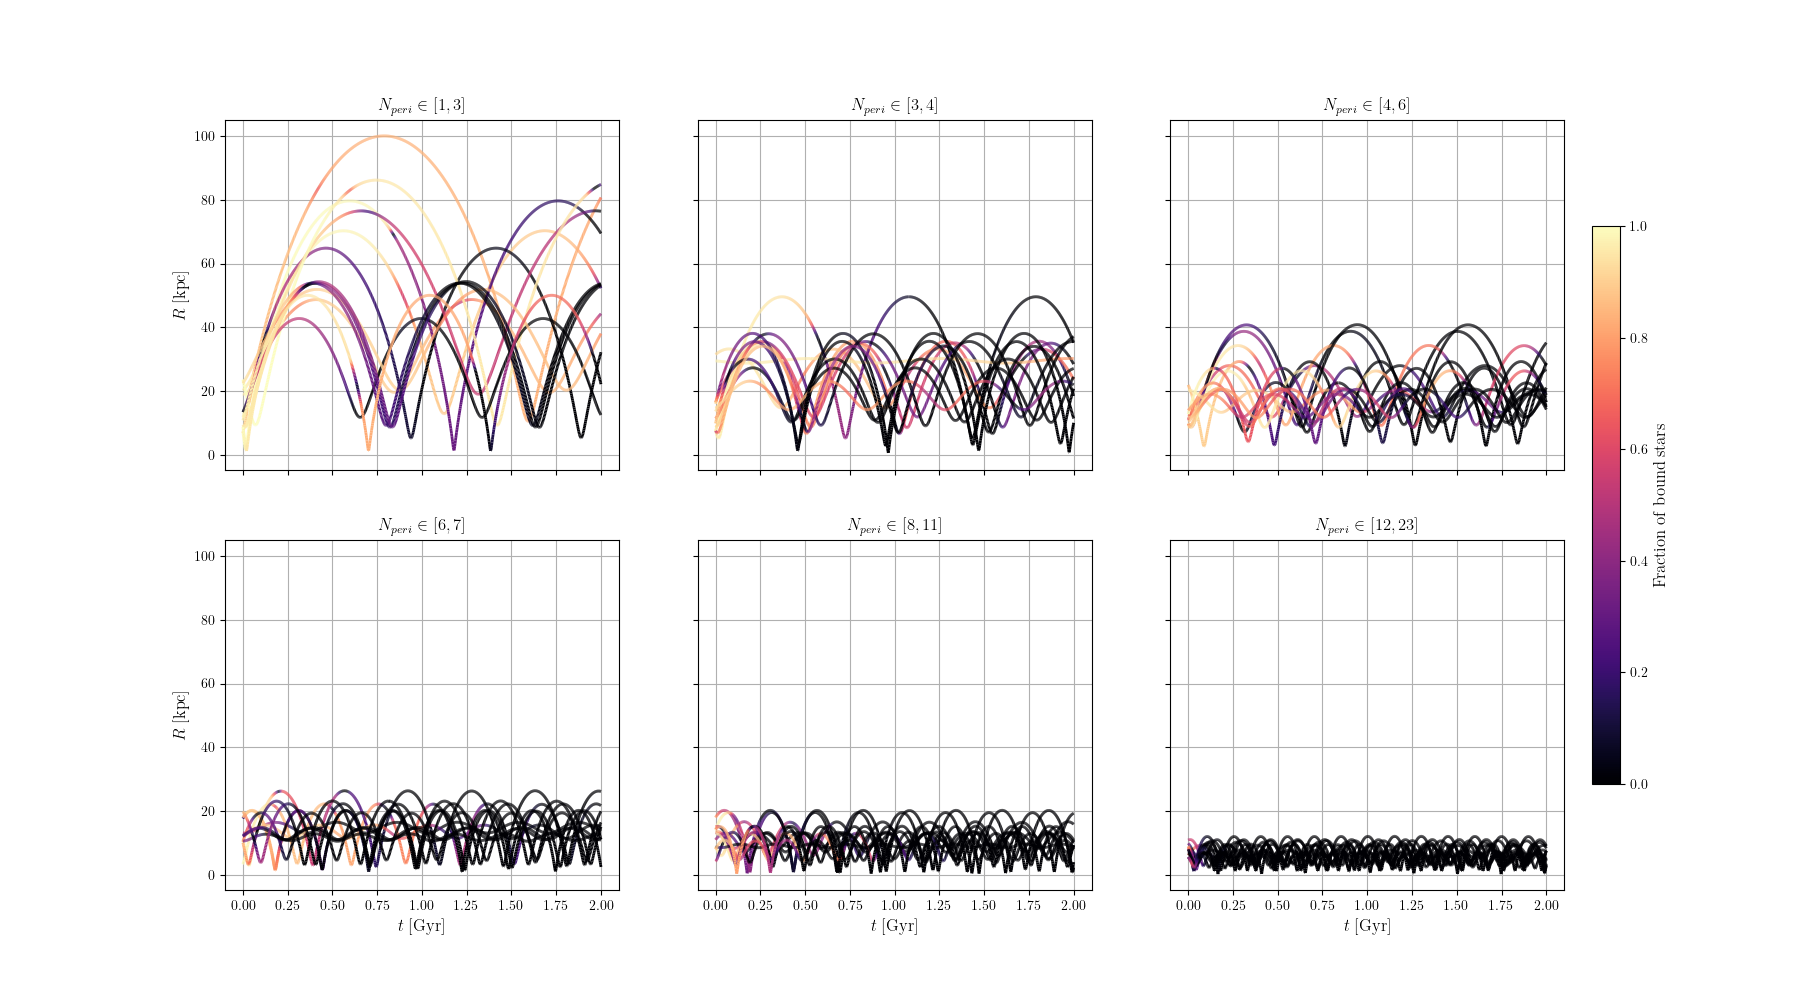

In [22]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from adri_plotstyle import init_plot_style

init_plot_style(14)

folder_orbits = "make_ICs/orbits/"
orbit_files = [f for f in os.listdir(folder_orbits) if f.startswith("orbit_") and f.endswith(".txt")]
folder_bound = "GNN-jed/labels_bound_stars/"
ic_list = [1, 3, 25, 47, 53, 69, 70]
ic_all = "all"

orbit_data = []

for orbits_file in orbit_files:
    ic_number = int(orbits_file.split('_')[1].split('.')[0])
    
    if ic_number in ic_list or ic_all == "all":
        full_path = os.path.join(folder_orbits, orbits_file)
        data = np.loadtxt(full_path, skiprows=1)
        
        r = np.sqrt(data[:, 0]**2 + data[:, 1]**2 + data[:, 2]**2)
        t = np.linspace(0, 2, len(r))
        
        r_a, r_p = np.max(r), np.min(r)
        e = (r_a - r_p) / (r_a + r_p)
        
        dr = np.diff(r)
        pericenters = np.where((dr[:-1] < 0) & (dr[1:] > 0))[0] + 1
        num_peri = len(pericenters)
        
        bound_frac = []
        t_snapshots = np.linspace(0, 2, 101)
        
        for snap_idx in range(101):
            label_file = os.path.join(folder_bound, f"IC_{ic_number}", f"B_L_snapshot_{snap_idx:04d}.npy")
            if os.path.exists(label_file):
                labels = np.load(label_file)
                bound_frac.append(np.sum(labels) / len(labels))
            else:
                bound_frac.append(np.nan)
                
        bound_interp = np.interp(t, t_snapshots, np.array(bound_frac))
        orbit_data.append((num_peri, ic_number, t, r, bound_interp, e))

orbit_data.sort(key=lambda x: x[0])
split_indices = np.array_split(range(len(orbit_data)), 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)
axes = axes.flatten()

lc = None 

for i, indices in enumerate(split_indices):
    ax = axes[i]
    ax.grid(True)
    if len(indices) == 0:
        continue
        
    n_min = orbit_data[indices[0]][0]
    n_max = orbit_data[indices[-1]][0]
    ax.set_title(rf'$N_{{peri}} \in [{n_min}, {n_max}]$', fontsize=12)
    
    for idx in indices:
        num_peri, ic_number, t, r, bound_interp, e = orbit_data[idx]
        
        points = np.array([t, r]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        colors = 0.5 * (bound_interp[:-1] + bound_interp[1:])
        
        lc = LineCollection(segments, cmap='magma')
        lc.set_array(colors)
        lc.set_linewidth(2)
        lc.set_clim(0.0, 1.0)
        
        ax.add_collection(lc)
    
    ax.autoscale()
    
    if i >= 3:
        ax.set_xlabel(r'$t\ \mathrm{[Gyr]}$')
    if i % 3 == 0:
        ax.set_ylabel(r'$R\ \mathrm{[kpc]}$')

if lc is not None:
    cbar = fig.colorbar(lc, ax=axes.tolist(), fraction=0.02, pad=0.02)
    cbar.set_label('$\mathrm{Fraction\ of\ bound\ stars}$')

plt.savefig("plots/R_vs_t_6panels_num_peri.png", dpi=600, bbox_inches='tight')
plt.show()